# Ariadne 0.3 — Research Workflow

This notebook follows the scientific story and figure order of
*Road to Ariadne 0.3*:

1. RSA straightening
2. Tip preservation
3. Fixed-spacing versus analytical continuous fronts
4. Random null models and the optimization landscape
5. Sampling-based classification of a real RSA

The notebook is intended for interactive exploration. Adjust the file path and
the sample counts at the top, then execute the cells in order.

## Setup and graph selection

In [1]:
%matplotlib inline

import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ariadne_roots import config
from ariadne_roots.pareto_functions import (
    get_critical_nodes,
    graph_costs,
    pareto_front,
    point_dist,
)
from ariadne_roots.quantify import estimate_rounds_for_region, get_graph_from_json
from ariadne_roots.research import (
    compare_fixed_spacing_granularity,
    compare_pareto_fronts_multi,
    comparaplot_four_random,
    pareto_steiner_fast_analytical_preserve_tips,
    pareto_steiner_fast_preserve_tips,
    pareto_steiner_fast_preserve_tips_fixed_spacing_binary_pareto,
    plot_randomization_landscape,
    plot_rsa_and_abstraction,
    plot_steiner_sequence_double,
    random_tree,
    random_tree_normalized,
)

# Representative graph used in the notebook.
GRAPH_PATH = Path(
    "tests/data/_set1_day1_20240429-125122_012_plantE_day1.json"
)

# Publication-scale settings. Reduce these for a quick exploratory run.
N_MST = 500
N_TOPDOWN = 200
N_BOTTOMUP = 300
N_ANALYTICAL = 500
N_LANDSCAPE = 500
N_SAMPLES = 5000
REGION_FACTOR = 0.75

config.length_scale_factor = 1.0
config.length_scale_unit = "px"

G = get_graph_from_json(GRAPH_PATH)
H = G.to_undirected()

# The algorithms use edge weights as Euclidean distances.
for u, v in H.edges():
    if "weight" not in H[u][v]:
        H[u][v]["weight"] = point_dist(
            H.nodes[u]["pos"], H.nodes[v]["pos"]
        )

print(f"Loaded: {GRAPH_PATH.name}")
print(f"Nodes: {H.number_of_nodes()}, edges: {H.number_of_edges()}")
print(f"Critical nodes: {len(get_critical_nodes(H))}")

Loaded: _set1_day1_20240429-125122_012_plantE_day1.json
Nodes: 87, edges: 86
Critical nodes: 18


## 1. The digitized RSA and its straightened representation

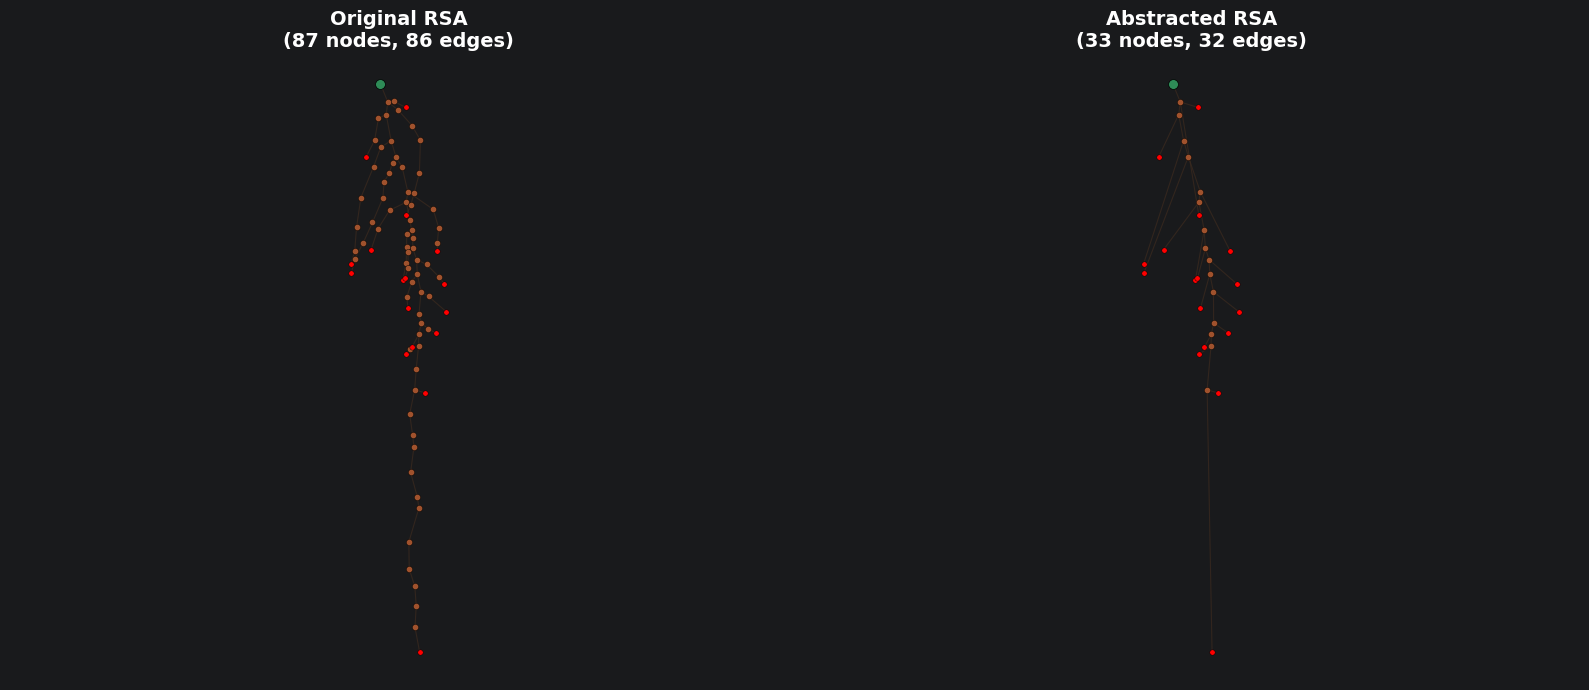

In [2]:
fig, axes = plot_rsa_and_abstraction(H)
plt.show()

## 2. Tip preservation

The original greedy Steiner construction may consume tips as internal branch
points. The tip-preserving construction keeps every original tip terminal.

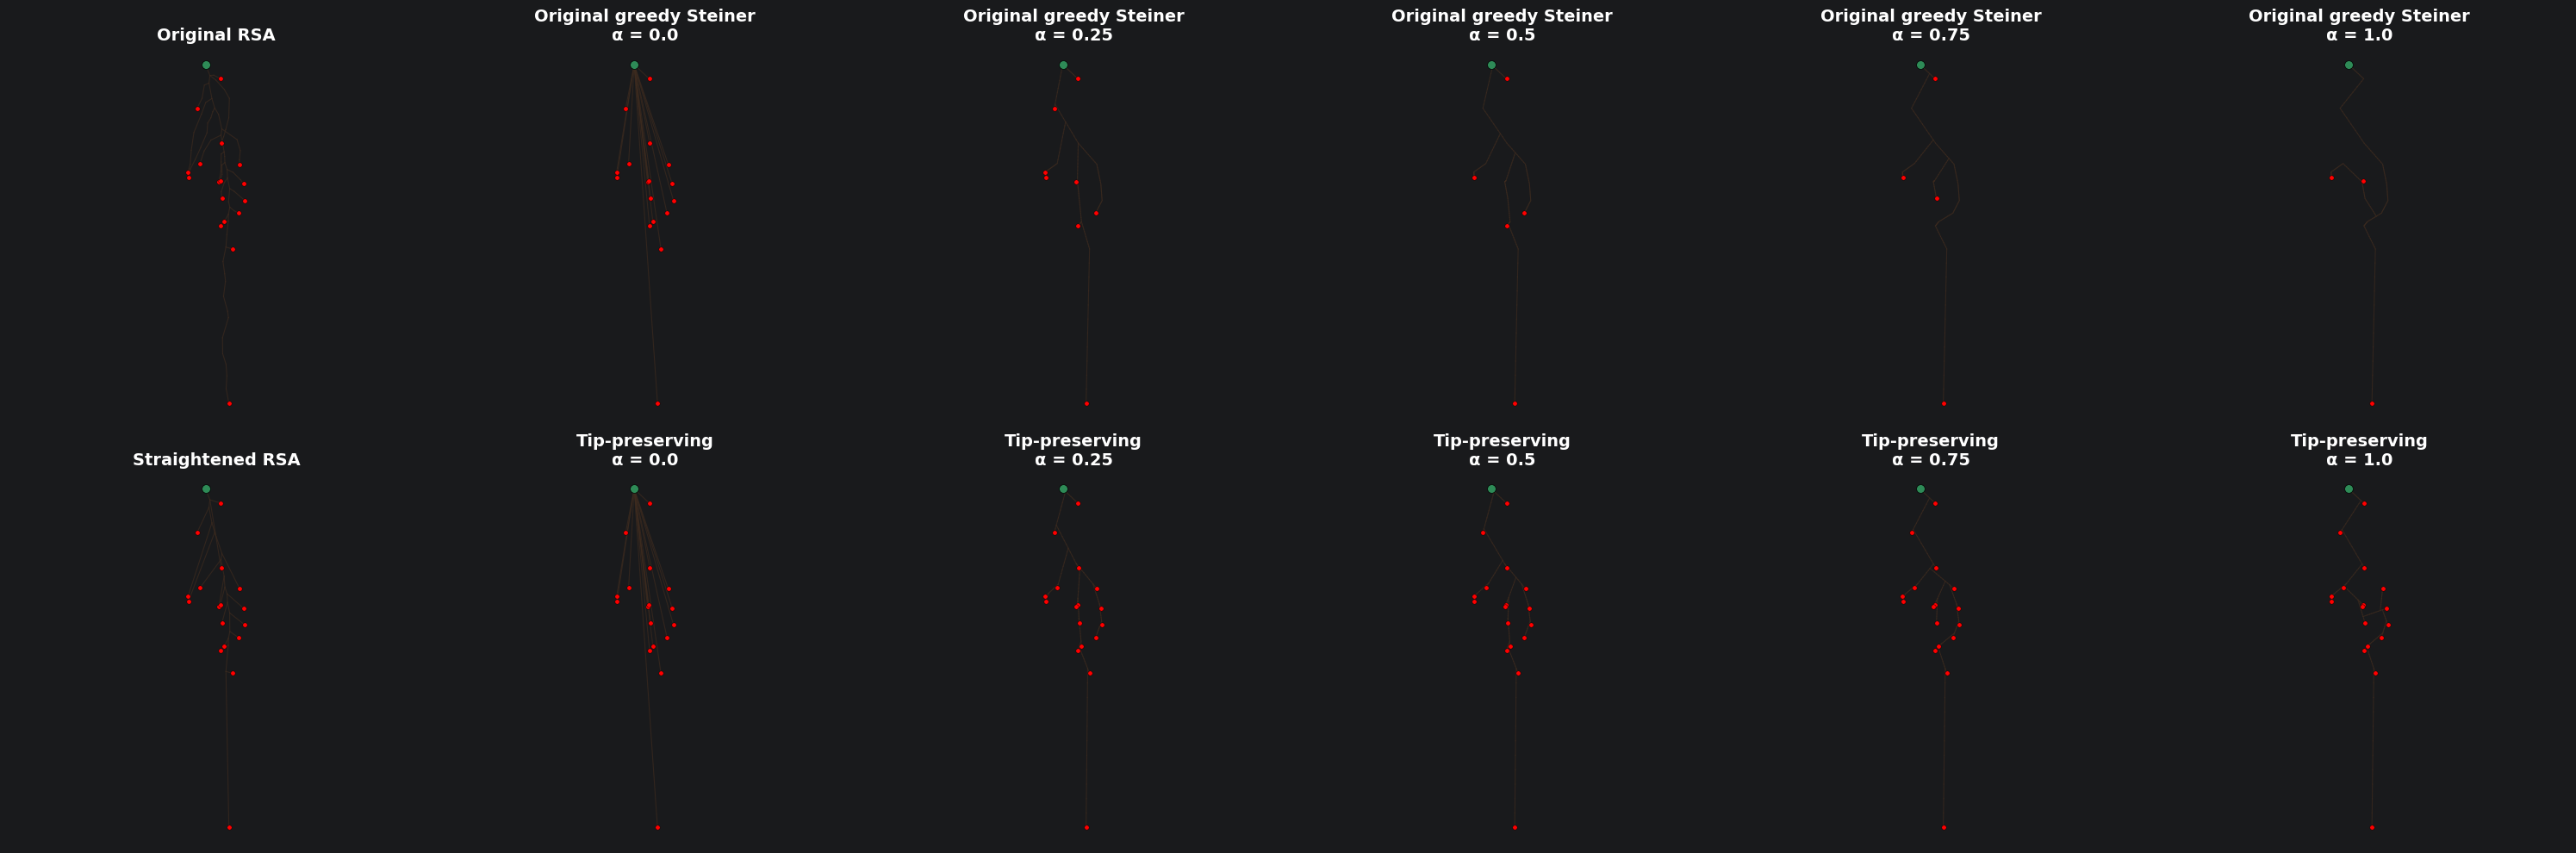

In [4]:
# Import the legacy/original generator under an explicit name.
from ariadne_roots.research import pareto_steiner_fast as original_steiner

fig = plot_steiner_sequence_double(
    H,
    original_steiner,
    pareto_steiner_fast_preserve_tips,
    alphas=[0.0, 0.25, 0.5, 0.75, 1.0],
    label_1="Original greedy Steiner",
    label_2="Tip-preserving",
)
plt.show()

## 3. Fixed-spacing versus analytical continuous fronts

Current front points: 82
Actual straightened tree: (7856.1637430625005, 21751.421516739985)
Processing graph 1/1...
  Tip-preserving greedy...
  Fixed-spacing binary (spacing = 0.5 × min LR length)...
  Analytical continuous...


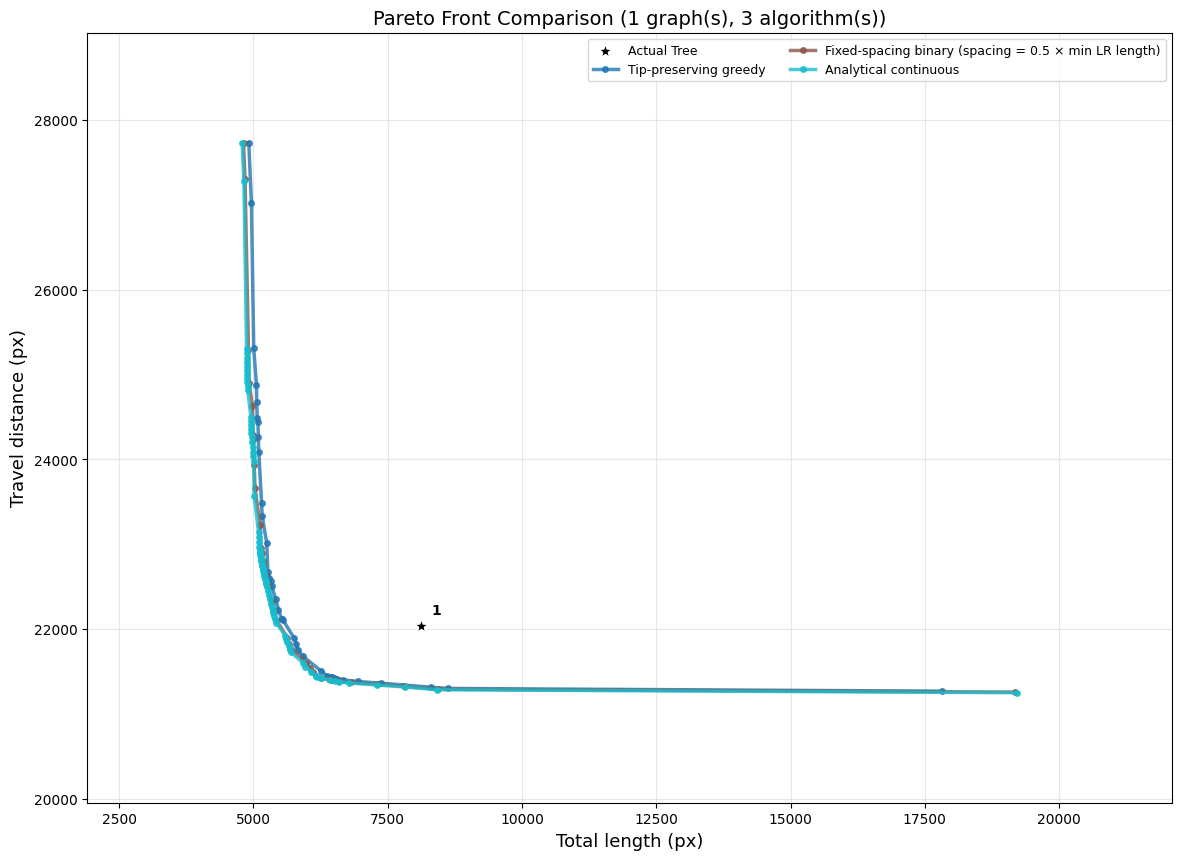

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front Comparison (1 graph(s), 3 algorithm(s))'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [15]:
front, actual = pareto_front(H)

print(f"Current front points: {len(front)}")
print(f"Actual straightened tree: {actual}")

compare_pareto_fronts_multi(
    H,
    [
        pareto_steiner_fast_preserve_tips,
        pareto_steiner_fast_preserve_tips_fixed_spacing_binary_pareto,
        pareto_steiner_fast_analytical_preserve_tips,
    ],
    labels=[
        "Tip-preserving greedy",
        "Fixed-spacing binary (spacing = 0.5 × min LR length)",
        "Analytical continuous",
    ],
)

The fixed-spacing construction converges toward the analytical continuous
front as its spacing becomes finer.

Computing continuous Pareto front...
Computing fixed-spacing front (spacing_factor=0.2)...
Computing fixed-spacing front (spacing_factor=0.4)...
Computing fixed-spacing front (spacing_factor=0.6)...
Computing fixed-spacing front (spacing_factor=0.8)...
Computing fixed-spacing front (spacing_factor=1.0)...


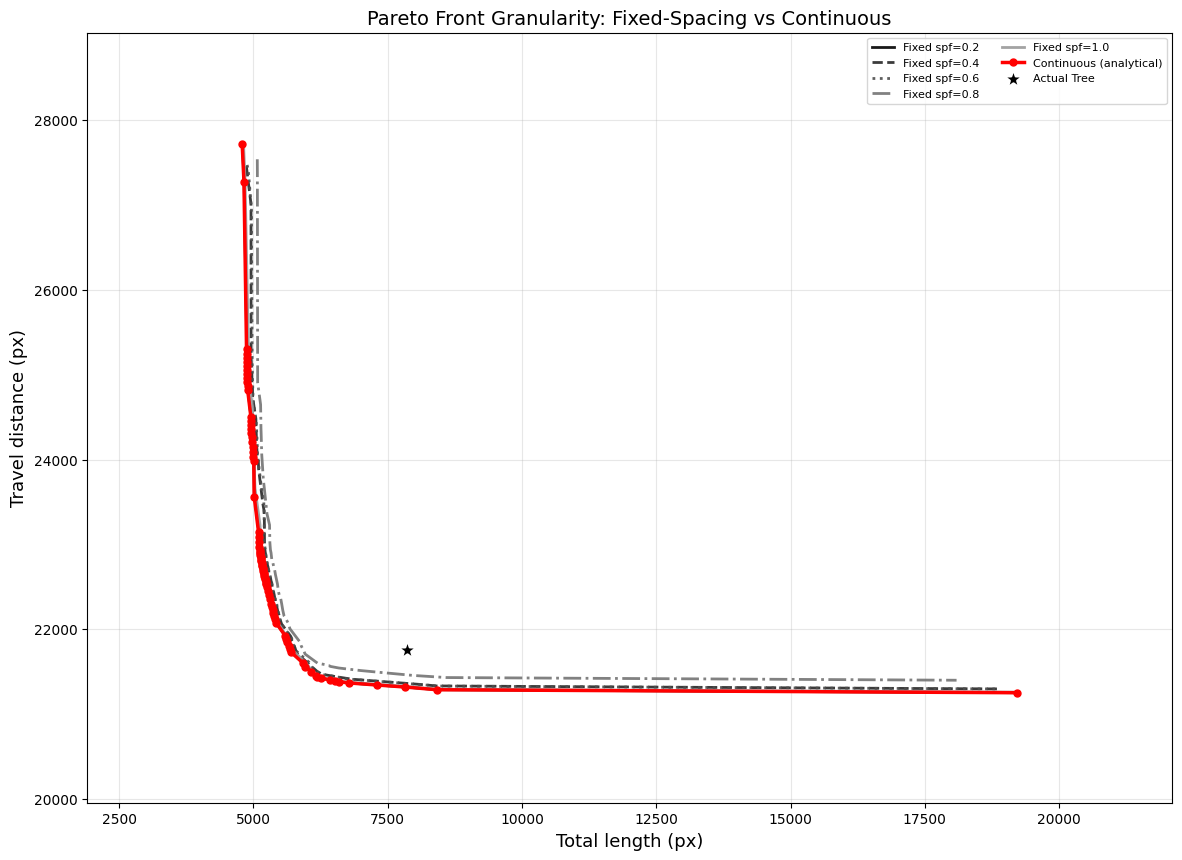

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front Granularity: Fixed-Spacing vs Continuous'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [17]:
compare_fixed_spacing_granularity(
    H,
    spacing_list=[0.2, 0.4, 0.6, 0.8, 1.0],
    min_length_factor=0.5,
)

## 4. Random null models

The original random spanning-tree null model is corrected by normalizing travel
distance to the number of tips in the generated tree.

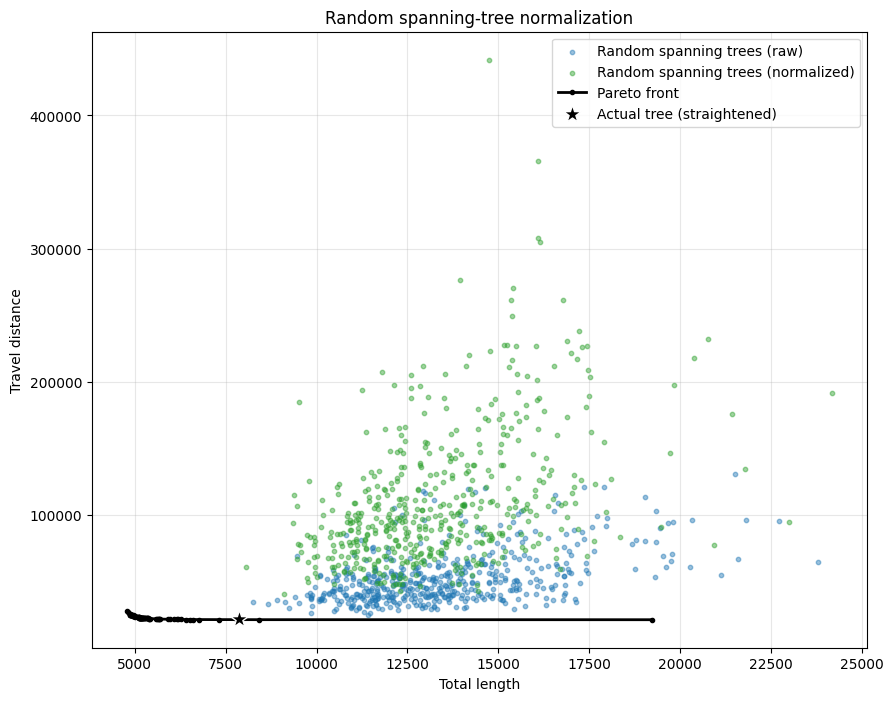

In [18]:
costs_raw, _ = random_tree(H, n=N_MST)
costs_normalized, _ = random_tree_normalized(H, n=N_MST)

front, actual = pareto_front(H)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(
    [c[0] for c in costs_raw],
    [c[1] for c in costs_raw],
    s=10,
    alpha=0.45,
    color="tab:blue",
    label="Random spanning trees (raw)",
)
ax.scatter(
    [c[0] for c in costs_normalized],
    [c[1] for c in costs_normalized],
    s=10,
    alpha=0.45,
    color="tab:green",
    label="Random spanning trees (normalized)",
)
ax.plot(
    [p[0] for p in front.values()],
    [p[1] for p in front.values()],
    color="black",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Pareto front",
)
ax.scatter(
    actual[0],
    actual[1],
    marker="*",
    s=180,
    color="black",
    edgecolors="white",
    zorder=5,
    label="Actual tree (straightened)",
)
ax.set_xlabel("Total length")
ax.set_ylabel("Travel distance")
ax.set_title("Random spanning-tree normalization")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Four constrained random generators: corrected spanning tree, top-down,
bottom-up, and randomized analytical.

Generating random spanning trees (normalized)...
  Got 500 trees
Generating top-down trees...
    Base -> 87 (order 0)
    87 (order=0) -> 95 (internal, order=0)
    87 (order=0) -> 97 (internal, order=1)
    97 (order=1) -> 42 (tip, order=2)
    97 (order=1) -> 93 (internal, order=1)
    93 (order=1) -> 44 (tip, order=1)
    93 (order=1) -> 91 (internal, order=1)
    91 (order=1) -> 89 (internal, order=1)
    91 (order=1) -> 102 (internal, order=1)
    95 (order=0) -> 92 (internal, order=1)
    95 (order=0) -> 101 (internal, order=1)
    102 (order=1) -> 94 (internal, order=1)
    102 (order=1) -> 96 (internal, order=1)
    96 (order=1) -> 62 (tip, order=1)
    96 (order=1) -> 88 (internal, order=1)
    88 (order=1) -> 65 (tip, order=1)
    88 (order=1) -> 50 (tip, order=1)
    101 (order=1) -> 39 (tip, order=2)
    101 (order=1) -> 86 (tip, order=1)
    89 (order=1) -> 98 (internal, order=1)
    89 (order=1) -> 90 (internal, order=1)
    94 (order=1) -> 72 (tip, order=1)
    94 (orde

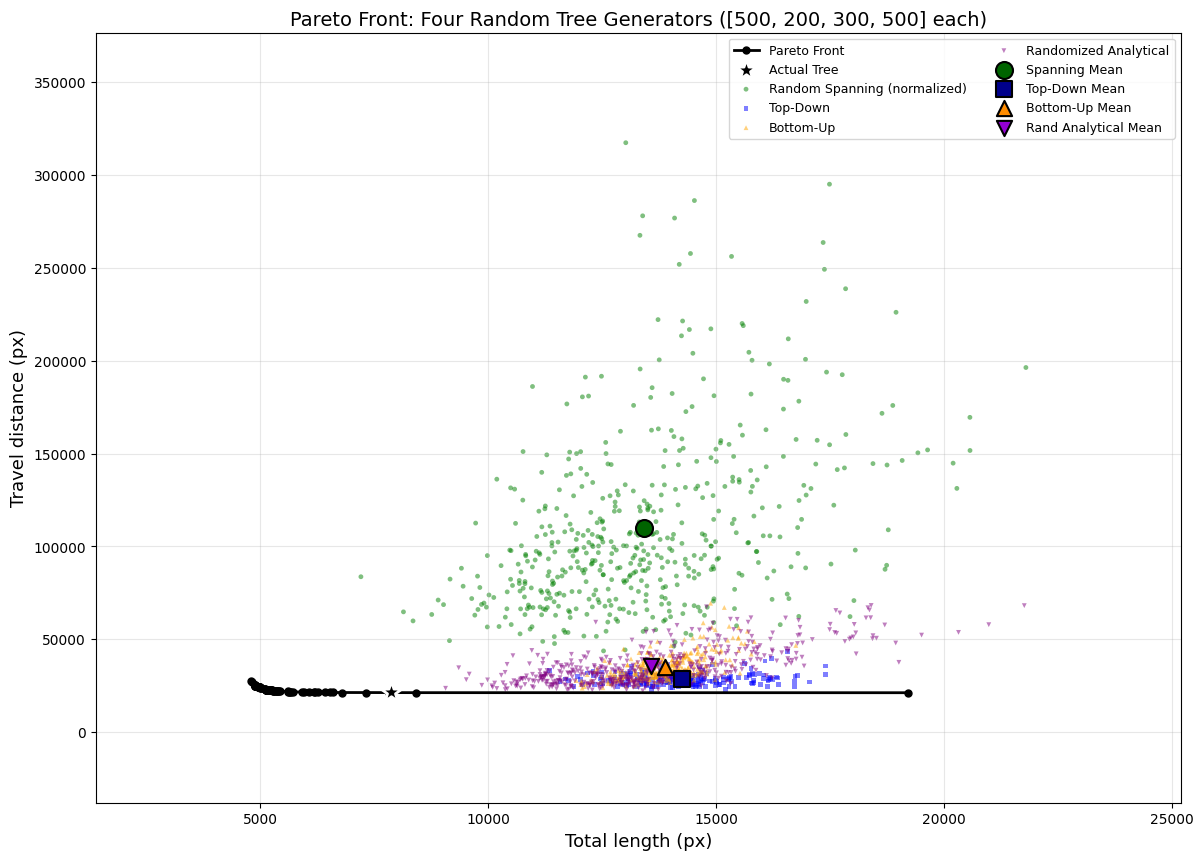

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front: Four Random Tree Generators ([500, 200, 300, 500] each)'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [19]:
comparaplot_four_random(
    H,
    n_random=[N_MST, N_TOPDOWN, N_BOTTOMUP, N_ANALYTICAL],
    verbose=False,
)

The optimization landscape interpolates between fully greedy and fully random
analytical constructions through the number of optimization rounds.

Generating 500 randomized trees...
Max rounds (fully Pareto): 17
  Generating 100 fully Pareto-optimal trees...
  Generating 100 fully random trees...
  Generating 300 trees with random rounds...
    Generated 50/300
    Generated 100/300
    Generated 150/300
    Generated 200/300
    Generated 250/300
    Generated 300/300
  Total: 500 trees, 100 optimal


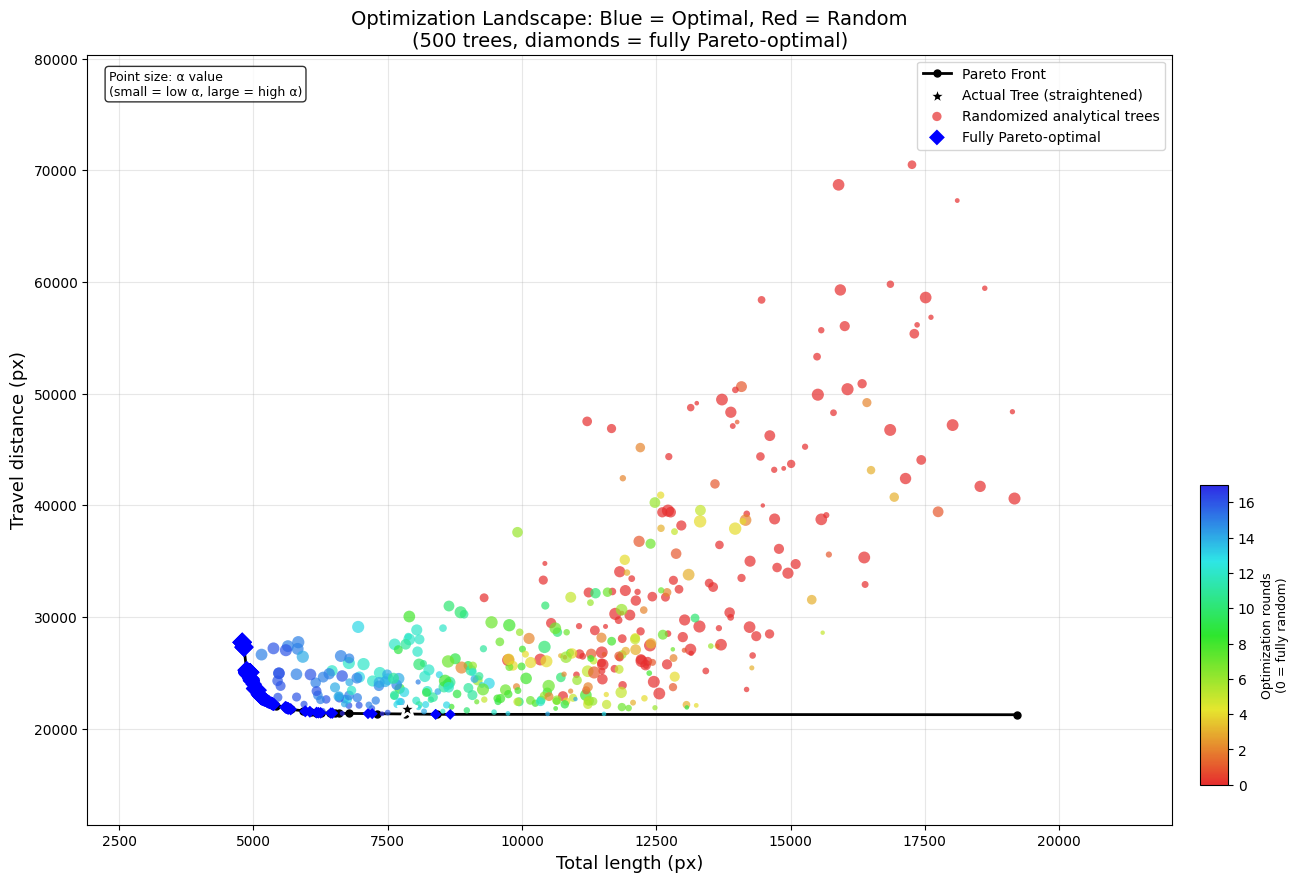

(<Figure size 1400x1000 with 2 Axes>,
 <Axes: title={'center': 'Optimization Landscape: Blue = Optimal, Red = Random\n(500 trees, diamonds = fully Pareto-optimal)'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [20]:
plot_randomization_landscape(H, n_trees=N_LANDSCAPE, dest=None)

## 5. Optimization level of the real RSA

Sample semi-random analytical architectures around the actual tree, retain the
ones inside the elliptical target region, and estimate the weighted mean
optimization level and trade-off direction alpha.

Actual tree: wiring=7856.2, travel=21751.4
Scaling distance to front: 1.0202
Ellipse radii: (116.4555, 322.4312)
Max rounds: 17
Generating 5000 semi-random trees...
  500/5000, inside: 0
  1000/5000, inside: 1
  1500/5000, inside: 2
  2000/5000, inside: 2
  2500/5000, inside: 2
  3000/5000, inside: 2
  3500/5000, inside: 3
  4000/5000, inside: 3
  4500/5000, inside: 3
  5000/5000, inside: 4

Total inside region: 4

Weighted results (n_inside=4, n_eff=2.2):
  Mean rounds: 13.42 (normalized: 0.789)
  95% CI: [10.55, 16.28] (normalized: [0.621, 0.958])
  Mean alpha: 0.075
  95% CI: [-0.082, 0.233]


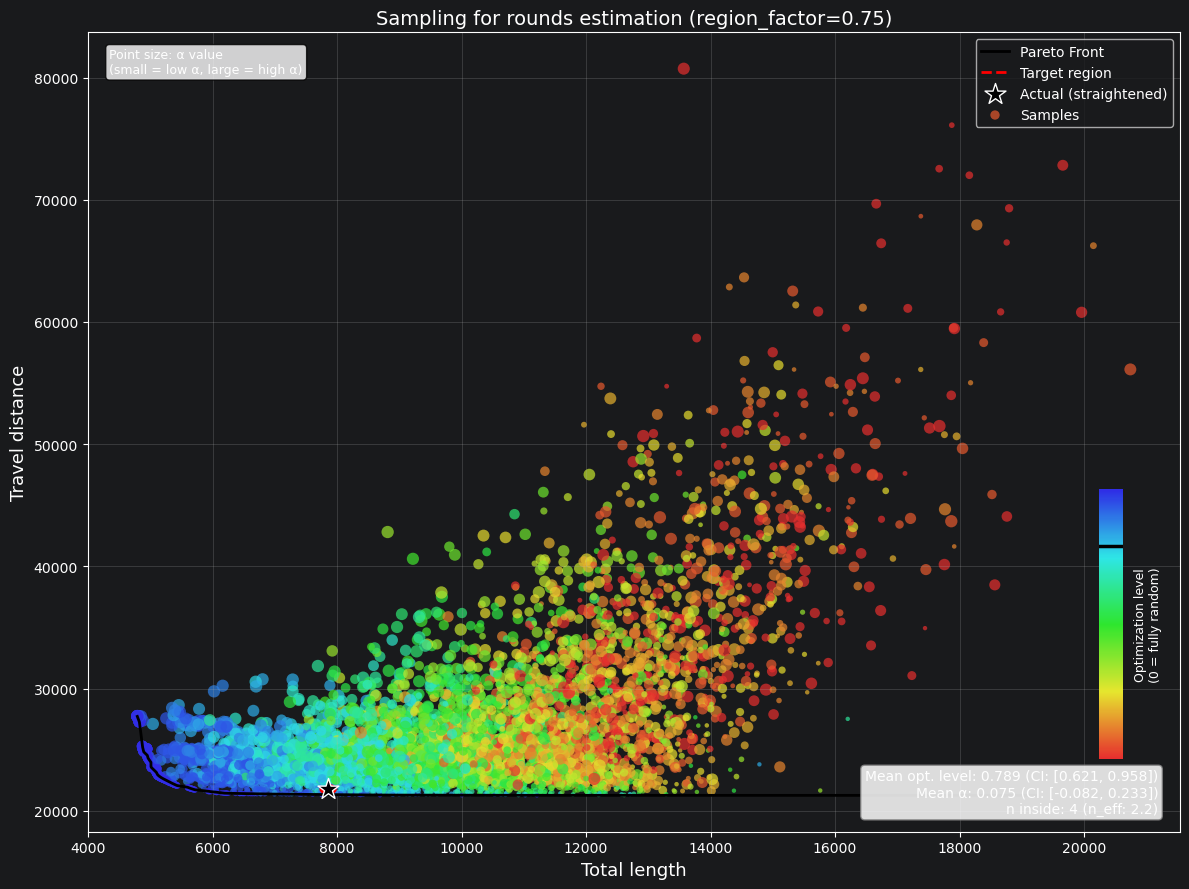

Weighted results
  mean optimization level: 0.7892436466041811 (CI: 0.6208749465712177, 0.9576123466371445)
  mean alpha: 0.07524527541923205 (CI: -0.0821593594988828, 0.2326499103373469)
  n inside: 4


In [3]:
front, actual = pareto_front(H)

sampling = estimate_rounds_for_region(
    H,
    n_samples=N_SAMPLES,
    region_factor=REGION_FACTOR,
    plot=True,
    show=True,
    front=front,
    actual=actual,
    verbose=True,
)

print("Weighted results")
print(
    "  mean optimization level:",
    sampling["mean_rounds_normalized"],
    f"(CI: {sampling['ci_low_normalized']}, {sampling['ci_high_normalized']})",
)
print(
    "  mean alpha:",
    sampling["mean_alpha"],
    f"(CI: {sampling['alpha_ci_low']}, {sampling['alpha_ci_high']})",
)
print("  n inside:", sampling["n_inside"])

## Notes

- `N_MST`, `N_TOPDOWN`, `N_BOTTOMUP`, `N_ANALYTICAL`, `N_LANDSCAPE`, and
  `N_SAMPLES` control the runtime.
- The reference-document values are 500, 200, 300, 500, 500, and 5000.
- All computations are performed before their plots, so individual cells can be
  rerun without rebuilding the rest of the notebook.